# State-conditioned Gaussian-mixture fixed point

This notebook runs `self_consistent_conditional_gmm_solver.py`. Each state-conditioned prior has $K$ full-covariance Gaussian components, and their state-prior-weighted average is the observer-facing $3K$-component marginal prior.

For each candidate marginal $p=\sum_s P(S=s)p_s$, the solver unrolls the geometric random age using the analytic denoiser $F_p$, fits new conditional GMMs, matches components, and damps the parameters. If the likelihood and state prior are invariant under exchanging S1/Cough with S2/Scratch, the solver fits their pooled, reflected samples and makes $p_{S2}$ the exact reflection of $p_{S1}$. Otherwise it fits all three conditionals independently. Healthy is never constrained.

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from self_consistent_conditional_gmm_solver import (
    has_sickness_exchange_symmetry, simulate_fixed_age_distributions,
    simulate_fixed_sequence, solve_conditional_gmm_fixed_point,
)
from self_consistent_gmm_solver import (
    default_basis, gmm_logpdf, gmm_moments, logbelief_to_probability,
    signal_displacements, simplex_frame, simplex_histogram,
)

np.set_printoptions(precision=4, suppress=True)

## Parameters

In [85]:
STATES = ['Healthy', 'Sickness 1', 'Sickness 2']
L = np.array([
    [0.70, 0.20, 0.20],
    [0.15, 0.60, 0.20],
    [0.15, 0.20, 0.60],
])
# L = np.array([
#     [0.70, 0.10, 0.10],
#     [0.15, 0.60, 0.30],
#     [0.15, 0.30, 0.60],
# ])
STATE_PRIOR = np.ones(3) / 3

COMPONENT_COUNTS = [5, 10, 15, 20]  # Use [10] for a faster single fit.
PLOT_COMPONENTS = 20
OBS_NOISE_SIGMA = .85 #.75 is not bad # 0.15
AGE_LAMBDA = 0.95
SAMPLES_PER_STATE = 5000
MAX_AGE = 80
INITIAL_SCALE = 2.0
MIN_STD = 0.20  # Prevents nearly singular needle components.
DAMPING = 0.50
MAX_ITERATIONS = 30
EM_MAX_ITERATIONS = 150
RESIDUAL_TOLERANCE = 0.05
MOMENT_TOLERANCE = 0.01
PATIENCE = 3
RANDOM_SEED = 15
STRATIFIED_DRAWS = True

LOG_LIMIT = 18
SLICE_VALUES = np.array([-8, -4, -2, 0, 2, 4, 8])
SIMPLEX_BINS = 50
SIMPLEX_QMC_POWER = 14
FIXED_AGES = np.array([5, 7, 10, 15])
FIXED_AGE_SAMPLES = 20000
FIXED_AGE_BINS = 80
POLARIZATION_SAMPLES = 20000
POLARIZATION_BINS = 120

print('S1/S2 symmetry:', has_sickness_exchange_symmetry(L, STATE_PRIOR))

S1/S2 symmetry: True


## Run projected fixed points

In [86]:
results = {}
for n_components in COMPONENT_COUNTS:
    print(f'\n--- K = {n_components} per state ---')
    results[n_components] = solve_conditional_gmm_fixed_point(
        L, n_components=n_components, noise_sigma=OBS_NOISE_SIGMA,
        age_lambda=AGE_LAMBDA, samples_per_state=SAMPLES_PER_STATE,
        max_age=MAX_AGE, initial_scale=INITIAL_SCALE, min_std=MIN_STD,
        damping=DAMPING, max_iterations=MAX_ITERATIONS,
        em_max_iterations=EM_MAX_ITERATIONS,
        residual_tolerance=RESIDUAL_TOLERANCE,
        moment_tolerance=MOMENT_TOLERANCE, patience=PATIENCE,
        seed=RANDOM_SEED, stratified=STRATIFIED_DRAWS,
        state_prior=STATE_PRIOR,
    )

conditionals, marginal, history, mapped_by_state = results[PLOT_COMPONENTS]


--- K = 5 per state ---
S1/S2 symmetry: used
iter 01 | max excess W=1.7638 | trace=8.640 -> 13.460
iter 02 | max excess W=1.2518 | trace=9.198 -> 16.767
iter 03 | max excess W=1.4962 | trace=11.964 -> 25.138
iter 04 | max excess W=1.6536 | trace=17.238 -> 35.969
iter 05 | max excess W=1.6555 | trace=25.061 -> 47.618
iter 06 | max excess W=1.5127 | trace=34.918 -> 59.353
iter 07 | max excess W=1.3960 | trace=46.128 -> 70.834
iter 08 | max excess W=1.2412 | trace=57.841 -> 81.317
iter 09 | max excess W=1.0094 | trace=69.246 -> 89.315
iter 10 | max excess W=0.7948 | trace=79.513 -> 94.829
iter 11 | max excess W=0.6073 | trace=87.664 -> 98.150
iter 12 | max excess W=0.4937 | trace=93.428 -> 99.817
iter 13 | max excess W=0.3856 | trace=97.354 -> 100.400
iter 14 | max excess W=0.3499 | trace=99.390 -> 100.320
iter 15 | max excess W=0.3348 | trace=100.249 -> 99.826
iter 16 | max excess W=0.2848 | trace=100.347 -> 99.114
iter 17 | max excess W=0.2920 | trace=99.958 -> 98.364
iter 18 | max exc

In [87]:
conditionals, marginal, history, mapped_by_state = results[PLOT_COMPONENTS]

## Convergence and component-count comparison

Residuals are evaluated separately for the three conditionals; the plot shows the largest excess sliced-Wasserstein distance.

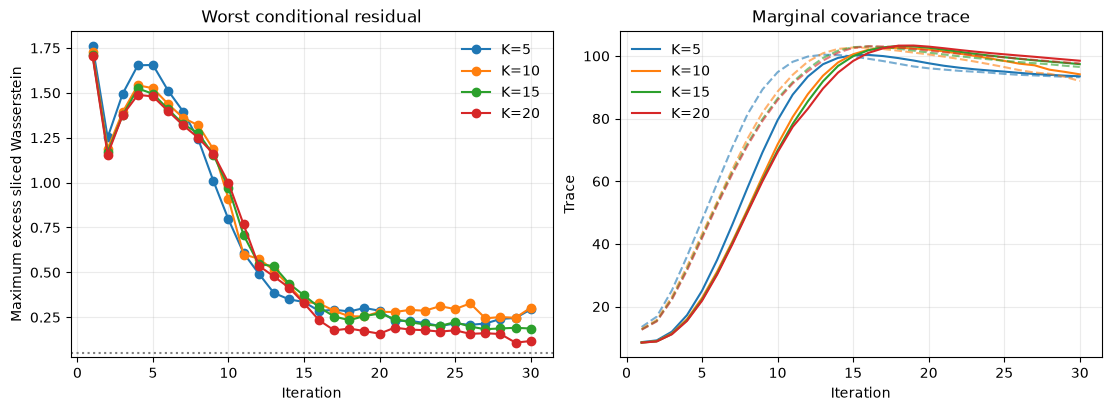

K= 5 per state (15 marginal) | max excess=0.2933 | trace=93.513
K=10 per state (30 marginal) | max excess=0.3029 | trace=94.144
K=15 per state (45 marginal) | max excess=0.1873 | trace=97.402
K=20 per state (60 marginal) | max excess=0.1175 | trace=98.485


In [88]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for n_components, (_, _, run_history, _) in results.items():
    iterations = [row['iteration'] for row in run_history]
    axes[0].plot(iterations, [row['max_excess_residual'] for row in run_history],
                 marker='o', label=f'K={n_components}')
    line, = axes[1].plot(iterations, [row['trace'] for row in run_history],
                         label=f'K={n_components}')
    axes[1].plot(iterations, [row['mapped_trace'] for row in run_history],
                 color=line.get_color(), linestyle='--', alpha=0.6)
axes[0].axhline(RESIDUAL_TOLERANCE, color='0.5', linestyle=':')
axes[0].set(title='Worst conditional residual', xlabel='Iteration',
            ylabel='Maximum excess sliced Wasserstein')
axes[1].set(title='Marginal covariance trace', xlabel='Iteration', ylabel='Trace')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
plt.show()

for n_components, (_, fit, run_history, _) in results.items():
    final = run_history[-1]
    print(f'K={n_components:2d} per state ({3*n_components:2d} marginal) | max excess={final["max_excess_residual"]:.4f} | trace={gmm_moments(fit)[1].trace():.3f}')

## Fitted conditional objects

Each conditional prior is represented by its own `weights`, `means`, and `covariances`. The marginal concatenates these components after multiplying their weights by `STATE_PRIOR`. When symmetry is used, the S2 parameters are the exact reflection of S1.

In [89]:
# for state, fit in zip(STATES, conditionals):
#     print(f'\n{state}')
#     print('weights:', fit.weights)
#     print('means:')
#     print(fit.means)
#     print('covariances:')
#     print(fit.covariances)

## Conditional and marginal priors in log-belief space

All four analytic densities use the same state-aligned coordinates and color scale.

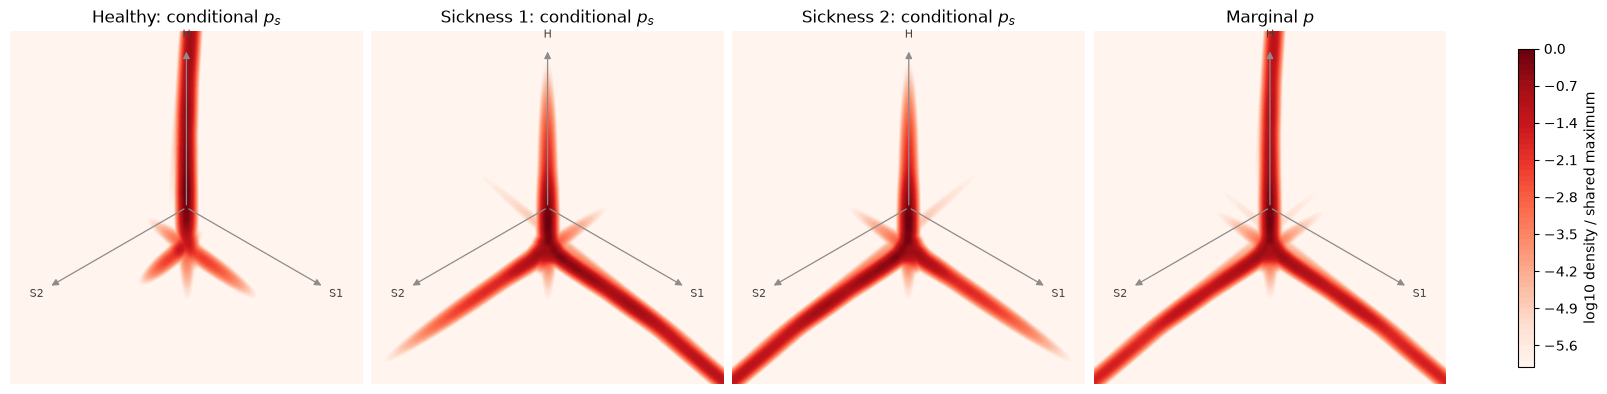

In [90]:
basis = default_basis()
frame = simplex_frame()
display_matrix = basis.T @ frame
display_to_z = np.linalg.inv(display_matrix)

def draw_state_axes(ax, limit=LOG_LIMIT):
    """Draw the three state directions in the symmetric display."""
    for name, direction in zip(['H', 'S1', 'S2'], frame):
        ax.annotate('', xy=0.90 * limit * direction, xytext=(0, 0),
                    arrowprops=dict(arrowstyle='-|>', color='0.55', lw=0.9),
                    zorder=3)
        ax.text(*(0.98 * limit * direction), name, ha='center',
                va='center', fontsize=8, color='0.25', zorder=3)

axis = np.linspace(-LOG_LIMIT, LOG_LIMIT, 401)
display_x, display_y = np.meshgrid(axis, axis, indexing='xy')
display_points = np.column_stack([display_x.ravel(), display_y.ravel()])
points = display_points @ display_to_z
panel_mixtures = conditionals + [marginal]
panel_titles = [f'{state}: conditional $p_s$' for state in STATES] + ['Marginal $p$']
panel_density = np.array([
    np.exp(gmm_logpdf(points, fit)).reshape(display_x.shape)
    for fit in panel_mixtures
])
panel_log_relative = np.log10(np.maximum(panel_density / panel_density.max(), 1e-8))
density_cmap = plt.colormaps['Reds']
levels = np.linspace(-6, 0, 61)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)
for ax, title, values in zip(axes, panel_titles, panel_log_relative):
    image = ax.contourf(display_x, display_y, np.maximum(values, levels[0]),
                        levels=levels, cmap=density_cmap)
    draw_state_axes(ax)
    ax.set_title(title)
    ax.set_xlim(-LOG_LIMIT, LOG_LIMIT)
    ax.set_ylim(-LOG_LIMIT, LOG_LIMIT)
    ax.set_aspect('equal')
    ax.axis('off')
fig.colorbar(image, ax=axes, shrink=0.72, label='log10 density / shared maximum')
plt.show()

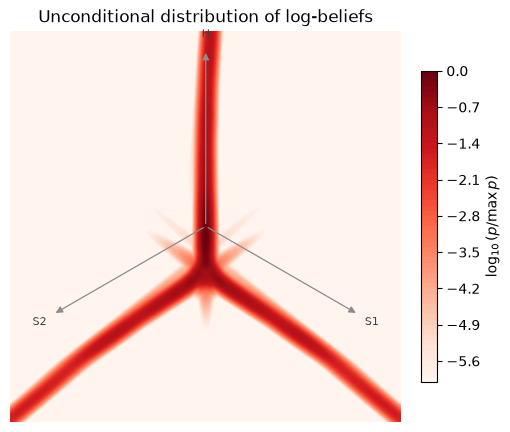

In [102]:
density = np.exp(gmm_logpdf(points, marginal)).reshape(display_x.shape)
log_relative = np.log10(np.maximum(density / density.max(), 1e-8))

fig, ax = plt.subplots(figsize=(5, 4.5), constrained_layout=True)
image = ax.contourf(display_x, display_y, np.maximum(log_relative, levels[0]),
                    levels=levels, cmap=density_cmap)
draw_state_axes(ax)
ax.set(title='Unconditional distribution of log-beliefs', xlim=(-LOG_LIMIT, LOG_LIMIT),
       ylim=(-LOG_LIMIT, LOG_LIMIT), aspect='equal')
ax.axis('off')
fig.colorbar(image, ax=ax, shrink=0.72, label=r'$\log_{10}(p / \max p)$')
plt.show()

## Fixed-age belief distributions conditional on S1

Set `wBayes` in the next cell to include or omit the noise-free Bayesian row. When shown, both rows use the same random signal sequences. Colors show mass per fixed log-space bin relative to that panel's maximum, with no smoothing.

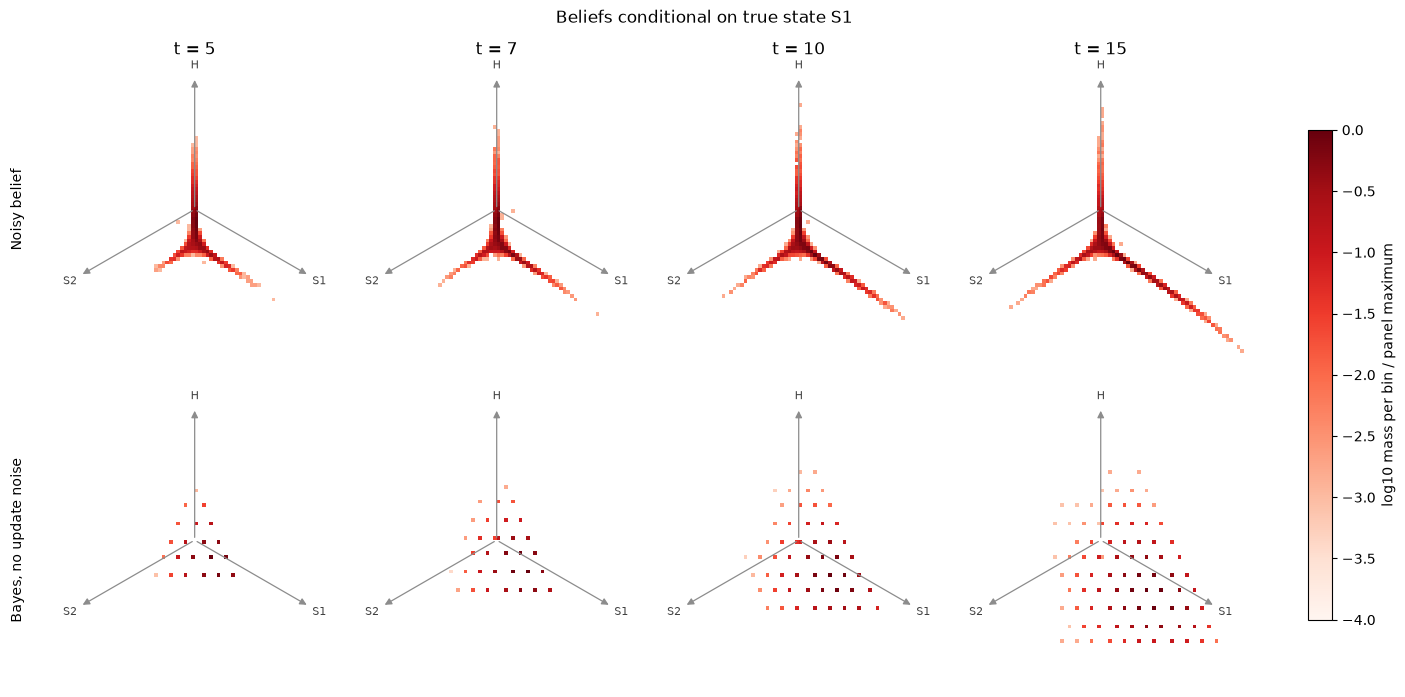

In [91]:
wBayes = True

fixed_noisy, fixed_bayes = simulate_fixed_age_distributions(
    marginal, L, OBS_NOISE_SIGMA, FIXED_AGES,
    n_samples=FIXED_AGE_SAMPLES, state=1, seed=RANDOM_SEED + 100,
)
edges = np.linspace(-LOG_LIMIT, LOG_LIMIT, FIXED_AGE_BINS + 1)
rows = [('Noisy belief', fixed_noisy)]
if wBayes:
    rows.append(('Bayes, no update noise', fixed_bayes))
fig, axes = plt.subplots(len(rows), len(FIXED_AGES),
                         figsize=(14, 3.5 * len(rows)),
                         constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (label, distributions) in enumerate(rows):
    for column, (age, values) in enumerate(zip(FIXED_AGES, distributions)):
        ax = axes[row, column]
        xy = values @ display_matrix
        mass = np.histogram2d(xy[:, 0], xy[:, 1], bins=[edges, edges])[0].T
        log_mass = np.ma.masked_where(
            mass == 0, np.log10(np.maximum(mass / mass.max(), 1e-4))
        )
        image = ax.pcolormesh(edges, edges, log_mass, cmap=density_cmap,
                              vmin=-4, vmax=0, shading='flat')
        draw_state_axes(ax)
        if row == 0:
            ax.set_title(f't = {age}')
        if column == 0:
            ax.text(-0.08, 0.5, label, transform=ax.transAxes, rotation=90,
                    ha='right', va='center')
        ax.set(xlim=(-LOG_LIMIT, LOG_LIMIT), ylim=(-LOG_LIMIT, LOG_LIMIT),
               aspect='equal')
        ax.axis('off')
fig.suptitle('Beliefs conditional on true state S1')
fig.colorbar(image, ax=axes, shrink=0.75,
             label='log10 mass per bin / panel maximum')
plt.show()

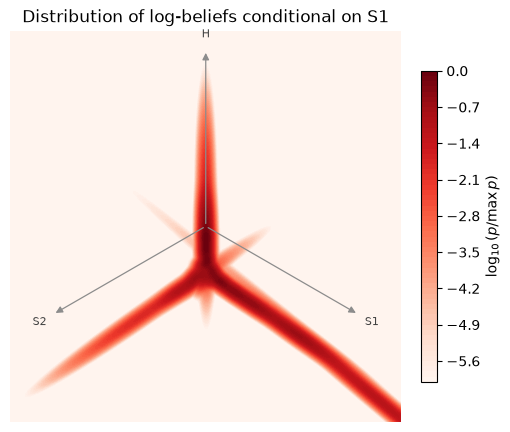

In [104]:
density = np.exp(gmm_logpdf(points, conditionals[1])).reshape(display_x.shape)
log_relative = np.log10(np.maximum(density / density.max(), 1e-8))

fig, ax = plt.subplots(figsize=(5, 4.5), constrained_layout=True)
image = ax.contourf(display_x, display_y, np.maximum(log_relative, levels[0]),
                    levels=levels, cmap=density_cmap)
draw_state_axes(ax)
ax.set(title='Distribution of log-beliefs conditional on S1',
       xlim=(-LOG_LIMIT, LOG_LIMIT), ylim=(-LOG_LIMIT, LOG_LIMIT),
       aspect='equal')
ax.axis('off')
fig.colorbar(image, ax=ax, shrink=0.72, label=r'$\log_{10}(p / \max p)$')
plt.show()

## Same-evidence polarization

Set `POLARIZATION_SEQUENCE` at the top of the next cell, using 0 = Whistle, 1 = Cough, and 2 = Scratch. Every observer receives that exact ordered sequence; only internal update noise differs. Negative $p_{S2}-p_{S1}$ favors S1 and positive values favor S2. The right panel shows the unsmoothed empirical mass in the symmetric 2D display of $H$.

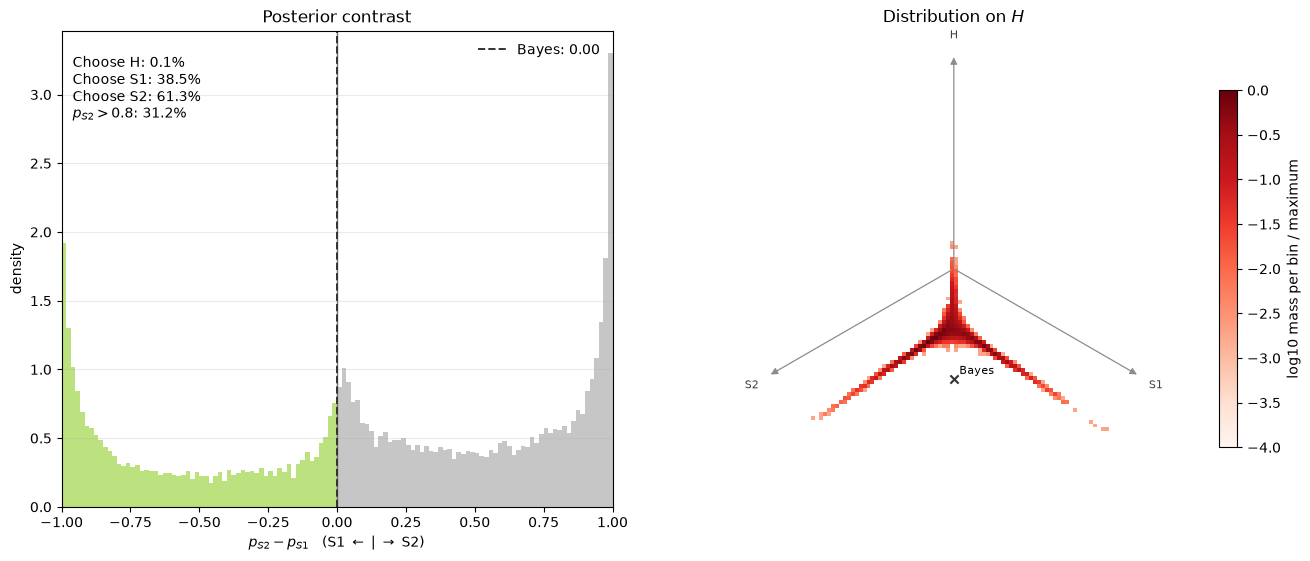

In [118]:
POLARIZATION_SEQUENCE = np.array([1, 2,] * 5 )  # 0=Whistle, 1=Cough, 2=Scratch.
#POLARIZATION_SEQUENCE = np.array([1, 2]*4)

same_evidence = simulate_fixed_sequence(
    marginal, L, OBS_NOISE_SIGMA, POLARIZATION_SEQUENCE,
    n_samples=POLARIZATION_SAMPLES, seed=RANDOM_SEED + 200,
)
probabilities = logbelief_to_probability(same_evidence, basis)
contrast = probabilities[:, 2] - probabilities[:, 1]
bayes_z = signal_displacements(L)[POLARIZATION_SEQUENCE].sum(axis=0)
bayes = bayes_z @ basis.T
bayes_probabilities = logbelief_to_probability(bayes_z, basis)
bayes_contrast = bayes_probabilities[2] - bayes_probabilities[1]
choice_rates = np.bincount(probabilities.argmax(axis=1), minlength=3) / len(probabilities)
strong_s2 = np.mean(probabilities[:, 2] > 0.8)

density, contrast_edges = np.histogram(
    contrast, bins=np.linspace(-1, 1, POLARIZATION_BINS + 1),
    density=True,
)
centers = 0.5 * (contrast_edges[:-1] + contrast_edges[1:])
sickness_colors = plt.cm.Set2(np.linspace(0, 1, 3))
bar_colors = [sickness_colors[1] if center < 0 else sickness_colors[2]
              for center in centers]

display_beliefs = same_evidence @ display_matrix
bayes_display = bayes_z @ display_matrix
belief_limit = max(LOG_LIMIT, 1.05 * np.max(np.abs(bayes_display)),
                   np.quantile(np.abs(display_beliefs), 0.995))
belief_edges = np.linspace(-belief_limit, belief_limit, POLARIZATION_BINS + 1)
belief_mass = np.histogram2d(
    display_beliefs[:, 0], display_beliefs[:, 1],
    bins=[belief_edges, belief_edges],
)[0].T
belief_log_mass = np.ma.masked_where(
    belief_mass == 0, np.log10(np.maximum(belief_mass / belief_mass.max(), 1e-4))
)

fig, (ax, belief_ax) = plt.subplots(1, 2, figsize=(13, 5.5),
                                      constrained_layout=True)
ax.bar(contrast_edges[:-1], density, width=np.diff(contrast_edges),
       align='edge', color=bar_colors, alpha=0.75, linewidth=0)
ax.axvline(0, color='0.45', lw=1)
ax.axvline(bayes_contrast, color='0.20', ls='--', lw=1.4,
           label=f'Bayes: {bayes_contrast:.2f}')
ax.text(0.02, 0.95,
        f'Choose H: {choice_rates[0]:.1%}\nChoose S1: {choice_rates[1]:.1%}'
        f'\nChoose S2: {choice_rates[2]:.1%}\n$p_{{S2}}>0.8$: {strong_s2:.1%}',
        transform=ax.transAxes, ha='left', va='top')
ax.set(title='Posterior contrast',
       xlabel=r'$p_{S2} - p_{S1}$   (S1 $\leftarrow$ | $\rightarrow$ S2)',
       ylabel='density', xlim=(-1, 1))
ax.grid(axis='y', alpha=0.25)
ax.legend(frameon=False)

image = belief_ax.pcolormesh(
    belief_edges, belief_edges, belief_log_mass, cmap=density_cmap,
    vmin=-4, vmax=0, shading='flat',
)
draw_state_axes(belief_ax, belief_limit)
belief_ax.scatter(*bayes_display, color='0.2', marker='x', s=35)
belief_ax.annotate('Bayes', bayes_display, xytext=(4, 4),
                   textcoords='offset points', fontsize=8)
belief_ax.set(title='Distribution on $H$',
              xlim=(-belief_limit, belief_limit),
              ylim=(-belief_limit, belief_limit), aspect='equal')
belief_ax.axis('off')
fig.colorbar(image, ax=belief_ax, shrink=0.75,
             label='log10 mass per bin / maximum')
#fig.suptitle(''.join(map(str, POLARIZATION_SEQUENCE)))
plt.show()

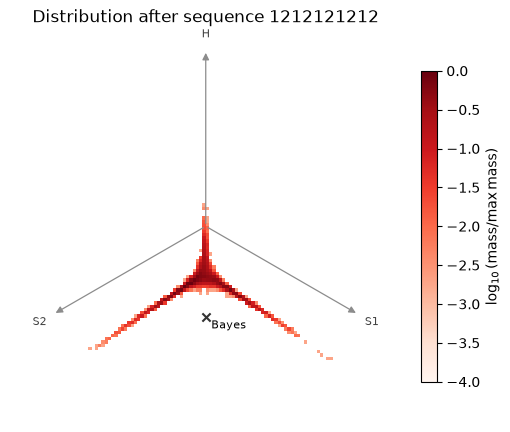

In [117]:
fig, ax = plt.subplots(figsize=(5, 4.5), constrained_layout=True)
image = ax.pcolormesh(belief_edges, belief_edges, belief_log_mass,
                      cmap=density_cmap, vmin=-4, vmax=0, shading='flat')
draw_state_axes(ax, belief_limit)
ax.scatter(*bayes_display, color='0.2', marker='x', s=35)
ax.annotate('Bayes', bayes_display, xytext=(4, -8),
            textcoords='offset points', fontsize=8)
ax.set(title='Distribution after sequence ' +
             ''.join(map(str, POLARIZATION_SEQUENCE)),
       xlim=(-belief_limit, belief_limit),
       ylim=(-belief_limit, belief_limit), aspect='equal')
ax.axis('off')
fig.colorbar(image, ax=ax, shrink=0.72,
             label=r'$\log_{10}(\mathrm{mass} / \max \mathrm{mass})$')
plt.show()

## Conditional Gaussian components

Dots are component means with area proportional to weight; ellipses contain 50% of each component.

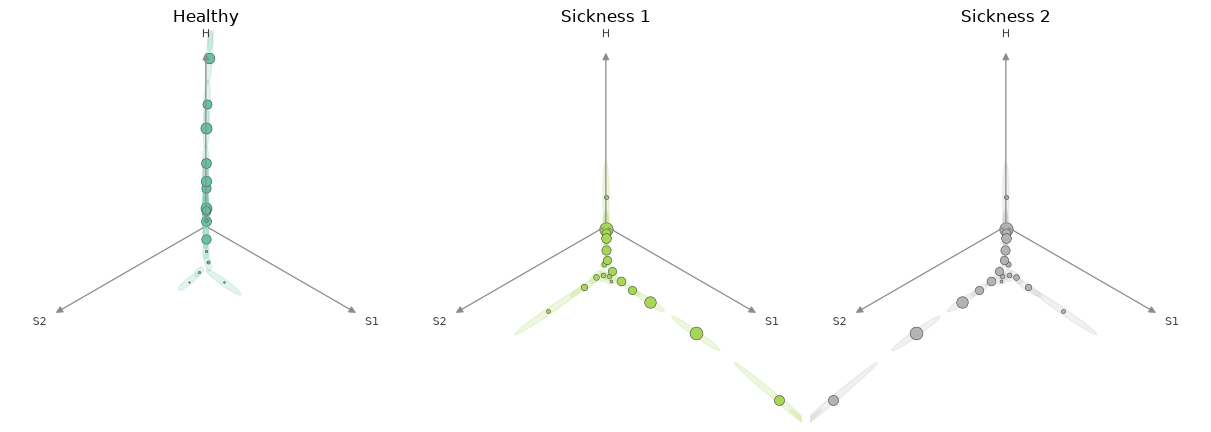

In [94]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), constrained_layout=True)
state_colors = plt.cm.Set2(np.linspace(0, 1, 3))
radius_50 = np.sqrt(2 * np.log(2))
for ax, state, fit, color in zip(axes, STATES, conditionals, state_colors):
    means = fit.means @ display_matrix
    covariances = [display_matrix.T @ covariance @ display_matrix
                   for covariance in fit.covariances]
    for weight, mean, covariance in zip(fit.weights, means, covariances):
        values, vectors = np.linalg.eigh(covariance)
        order = np.argsort(values)[::-1]
        values, vectors = values[order], vectors[:, order]
        angle = np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0]))
        width, height = 2 * radius_50 * np.sqrt(values)
        ax.add_patch(Ellipse(mean, width, height, angle=angle,
                             facecolor=color, edgecolor=color, alpha=0.18))
        ax.scatter(*mean, s=700 * weight, color=color, edgecolor='0.25', lw=0.4)
    draw_state_axes(ax)
    ax.set_title(state)
    ax.set_xlim(-LOG_LIMIT, LOG_LIMIT)
    ax.set_ylim(-LOG_LIMIT, LOG_LIMIT)
    ax.set_aspect('equal')
    ax.axis('off')
plt.show()

## Marginal density slices

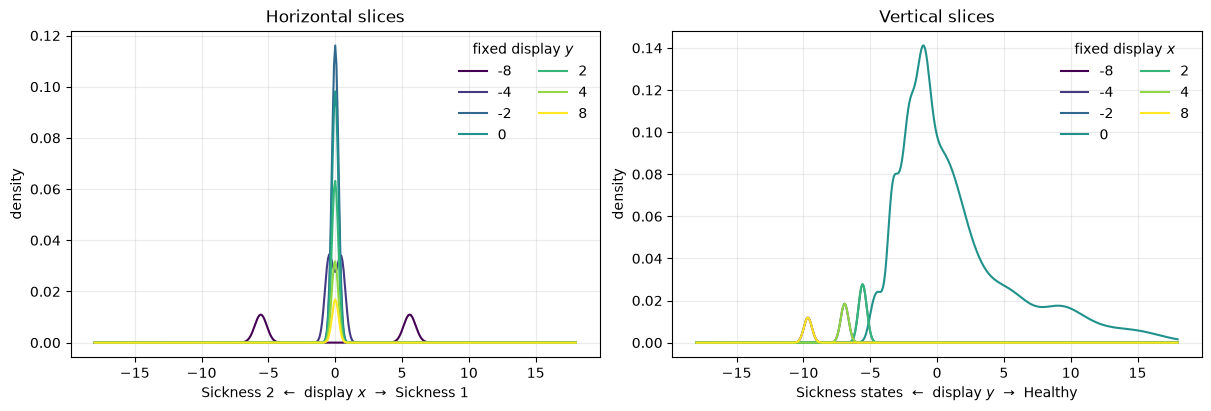

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(SLICE_VALUES)))
density_scale = 1 / abs(np.linalg.det(display_matrix))
for value, color in zip(SLICE_VALUES, colors):
    horizontal = np.column_stack([axis, np.full_like(axis, value)]) @ display_to_z
    vertical = np.column_stack([np.full_like(axis, value), axis]) @ display_to_z
    axes[0].plot(axis, density_scale * np.exp(gmm_logpdf(horizontal, marginal)),
                 color=color, label=f'{value:g}')
    axes[1].plot(axis, density_scale * np.exp(gmm_logpdf(vertical, marginal)),
                 color=color, label=f'{value:g}')
axes[0].set(title='Horizontal slices', xlabel='Sickness 2  ←  display $x$  →  Sickness 1', ylabel='density')
axes[1].set(title='Vertical slices', xlabel='Sickness states  ←  display $y$  →  Healthy', ylabel='density')
axes[0].legend(title='fixed display $y$', frameon=False, ncol=2)
axes[1].legend(title='fixed display $x$', frameon=False, ncol=2)
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

## Marginal prior in probability space

This displays mass per equal-area simplex bin using fixed low-discrepancy integration.

simplex histogram mass: 1.0000000000000937


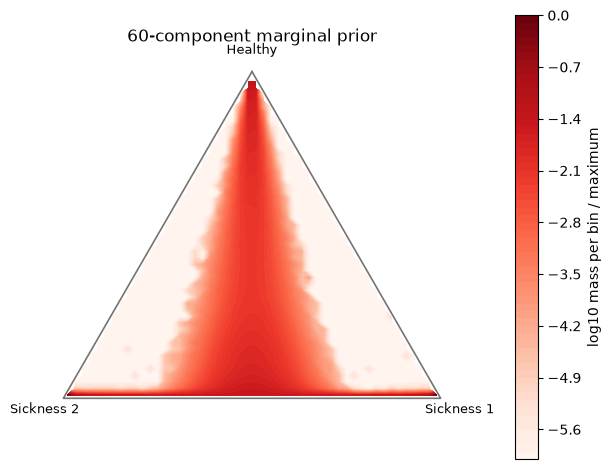

In [96]:
simplex_mass, x_edges, y_edges = simplex_histogram(
    marginal, n_bins=SIMPLEX_BINS, qmc_power=SIMPLEX_QMC_POWER, basis=basis,
)
print('simplex histogram mass:', simplex_mass.sum())
x = 0.5 * (x_edges[:-1] + x_edges[1:])
y = 0.5 * (y_edges[:-1] + y_edges[1:])
X, Y = np.meshgrid(x, y, indexing='xy')
healthy = (2 * Y + 1) / 3
sickness_1 = (1 - healthy) / 2 + X / np.sqrt(3)
inside = (healthy > 0) & (sickness_1 > 0) & (healthy + sickness_1 < 1)
relative = simplex_mass / simplex_mass.max()
log_relative = np.ma.masked_where(~inside, np.log10(np.maximum(relative, 1e-8)))
fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
image = ax.contourf(X, Y, np.maximum(log_relative, levels[0]),
                    levels=levels, cmap=density_cmap)
closed = np.vstack([frame, frame[0]])
ax.plot(closed[:, 0], closed[:, 1], color='0.45', lw=1.2)
for state, vertex in zip(STATES, frame):
    ax.text(*(1.10 * vertex), state, ha='center', va='center', fontsize=9)
ax.set_title(f'{3 * PLOT_COMPONENTS}-component marginal prior')
ax.set_xlim(-1.02, 1.02)
ax.set_ylim(-0.62, 1.10)
ax.set_aspect('equal')
ax.axis('off')
fig.colorbar(image, ax=ax, shrink=0.75, label='log10 mass per bin / maximum')
plt.show()